IMPORT LIBRARIES

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns

In [3]:
df = pd.read_csv("data/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [4]:
df 

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [5]:
df.head(10)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


In [6]:
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
print(df.nunique().sort_values())

print("\nAttrition distribution:")
print(df["Attrition"].value_counts(dropna=False))

print("\nAttrition percentages:")
print(
    df["Attrition"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Shape: (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   Bu

* Missing values
zero missing values in all 35 columns.
Decision: We don't currently need missing-value imputation for this dataset.
* Duplicate records
zero exact duplicate rows.
Decision: No exact duplicate rows need to be removed based on this check.
* Three constant columns
EmployeeCount — 1 unique value

Over18 — 1 unique value

StandardHours — 1 unique value
Decision: Plan to exclude these three columns from the predictive features. They contain no useful variation for Logistic Regression.
* EmployeeNumber
EmployeeNumber has 1,470 unique values for 1,470 rows.
Decision: Plan to exclude it from the model.
* target is imbalanced

Stayed: 1,233 employees (83.88%)

Left: 237 employees (16.12%)

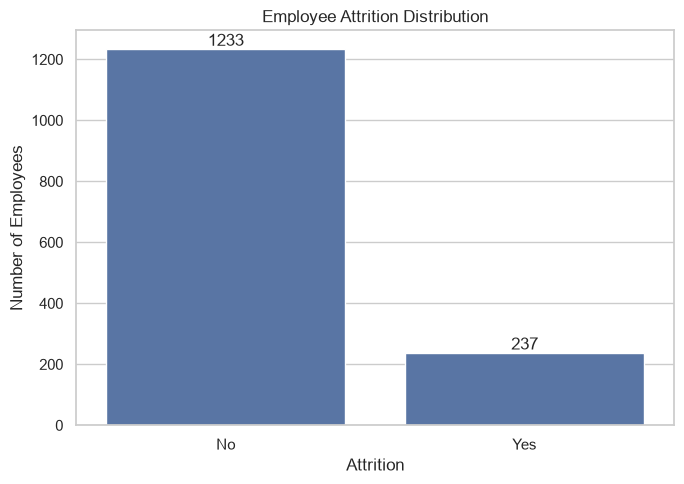

In [9]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 5))
ax = sns.countplot(x="Attrition", data=df, order=["No","Yes"])
for container in ax.containers:
    ax.bar_label(container)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

#### 1. Numerical feature distributions

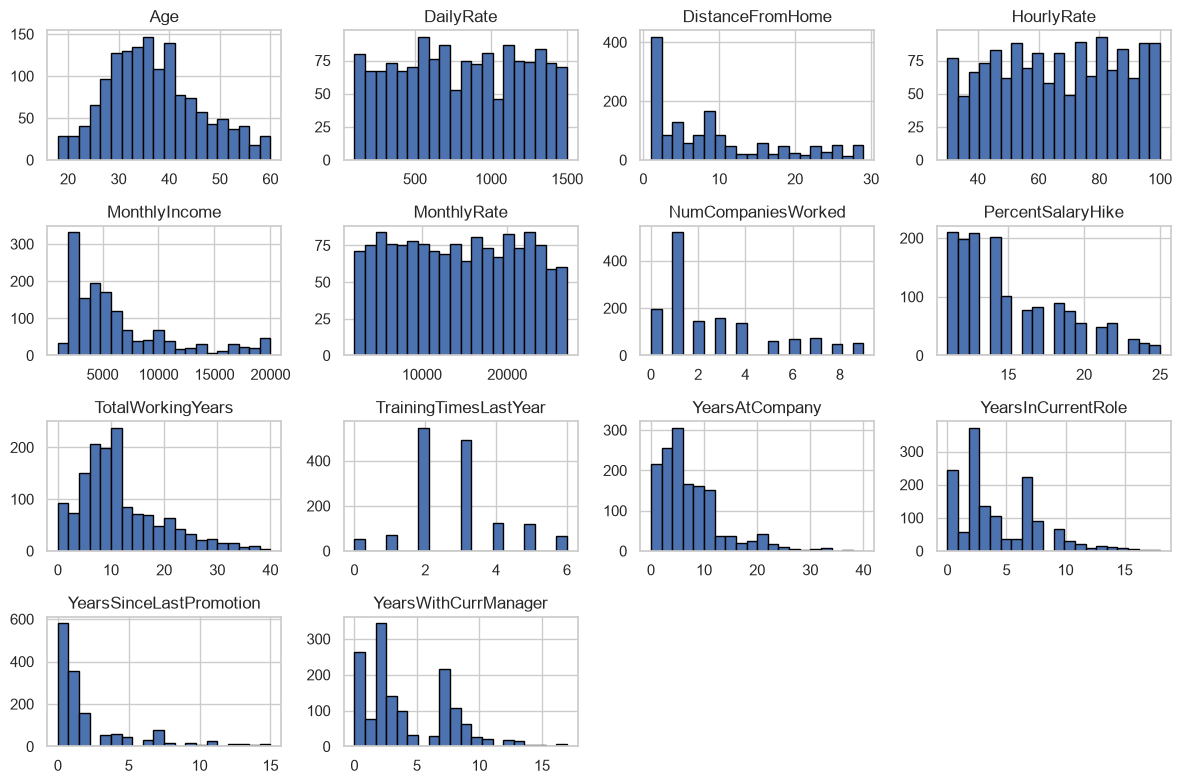

In [72]:
sns.set_theme(style="whitegrid")

# Continuous-like and count-based numerical features
num_cols = [
    "Age", "DailyRate", "DistanceFromHome", "HourlyRate",
    "MonthlyIncome", "MonthlyRate", "NumCompaniesWorked",
    "PercentSalaryHike", "TotalWorkingYears",
    "TrainingTimesLastYear", "YearsAtCompany",
    "YearsInCurrentRole", "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

# Exclude identifiers and constant columns
df[num_cols].hist(figsize=(12,8),bins=20,edgecolor="black")
plt.tight_layout()
plt.show()

1. Near-Normal Distribution
Age: Unimodal and approximately normal, centered around 30–40 years old. This indicates a predominantly early-to-mid-career workforce, with fewer employees below 25 or above 50.
2. Heavily Right-Skewed Distributions
MonthlyIncome: Strongly right-skewed, with most employees earning under $7,000 per month and a long tail extending up to $20,000 for senior executive roles.
    DistanceFromHome: Most employees live close to the office ( under 10 miles/units), while a smaller fraction commutes longer distances (15–30 units).
    TotalWorkingYears & YearsAtCompany: Both peak early (1–10 total working years and 1–5 years at the company), showing high representation among newer and mid-level hires.
    YearsSinceLastPromotion: Heavily concentrated at 0–1 years, showing that a significant portion of employees were recently promoted, while multi-year promotion lags are uncommon.
    PercentSalaryHike: Bounded between 11% and 25%, with the vast majority of employees receiving smaller hikes (11%–15%) and progressively fewer receiving top-tier raises.
3. Uniform Distributions
DailyRate, HourlyRate, and MonthlyRate: Spread almost evenly across their respective value ranges. Flat distributions like these strongly suggest synthetic or artificially generated data columns that carry little natural variance structure.   
4. Bimodal & Discrete Distributions
YearsInCurrentRole & YearsWithCurrManager: Show distinct bimodal peaks at approximately 2 years and 7 years. These double peaks highlight common retention and internal job-rotation cycles within the organization.
TrainingTimesLastYear: Highly discrete, clustering heavily around 2 and 3 training sessions annually.
NumCompaniesWorked: Peaks sharply at 1 company, representing early-career professionals or loyalists, with a secondary cluster around 2–4 companies.

#### 2. Numerical features vs Attrition

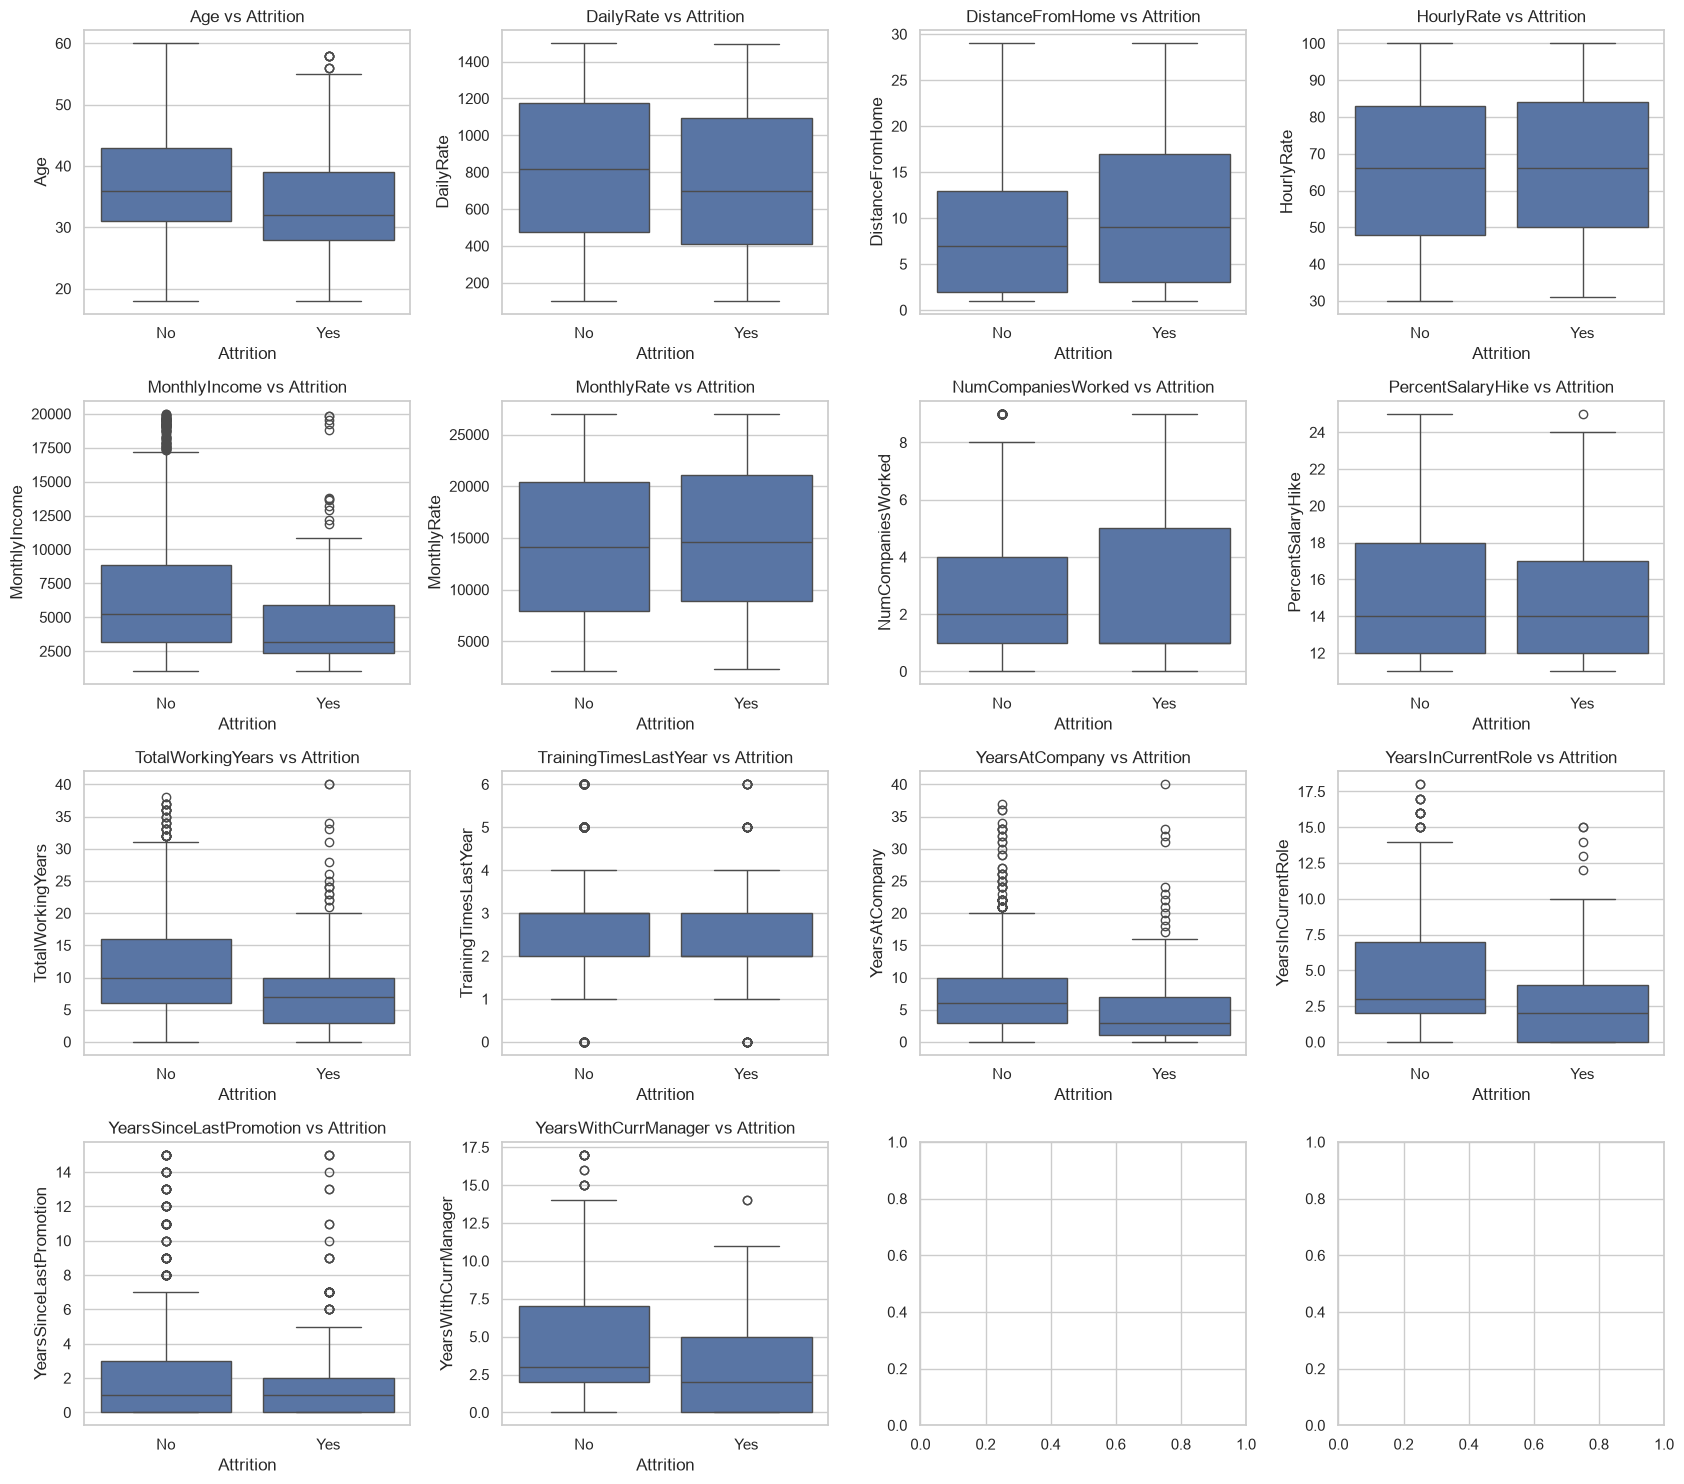

In [29]:
fig,axes = plt.subplots(4,4,figsize=(17,15))
axes = axes.flatten()

for i,col in enumerate(num_cols):
    sns.boxplot(
        data=df,
        x="Attrition",
        y=col,
        order=["No","Yes"],
        ax = axes[i] 
    )
    axes[i].set_title(f"{col} vs Attrition")
    axes[i].set_xlabel("Attrition")
    

plt.tight_layout()
plt.show()    
    

1. Key Drivers of Attrition (Strongest Separation)MonthlyIncome: Employees who leave (Yes) have significantly lower median monthly income (~$3,000) compared to those who stay (~$5,000).   Age: Younger employees display a higher attrition rate, with the median age of leaving employees around 32 compared to ~36 for retained staff.   YearsAtCompany: Attrition is heavily concentrated among newer hires (median tenure of ~3 years for Yes vs ~6 years for No).   TotalWorkingYears: Employees with less total work experience leave at higher rates (median ~7 years) compared to more experienced peers (median ~10 years).   YearsInCurrentRole: Employees in their role for 2 years or fewer show higher propensity to attrite compared to those with longer stability in their position.   2. Moderate Risk FactorsDistanceFromHome: Attrited employees have a higher upper quartile and median distance from home, suggesting longer commute times increase turnover risk.   NumCompaniesWorked: The upper quartile for Yes reaches up to 5 companies compared to 4 for No, indicating a slight increase in attrition among employees with a history of frequent job changes.   DailyRate: Shows a slight downward shift for the Yes group, though there is substantial box overlap.   3. Non-Differentiating Features (Weak/No Signal)HourlyRate & MonthlyRate: The box distributions, medians, and IQRs are virtually identical between No and Yes, indicating little to no direct correlation with attrition.   PercentSalaryHike: Median salary hikes (~14%) and spread are nearly identical across both groups.   TrainingTimesLastYear: Both groups exhibit an identical median of 3 training sessions and matching interquartile ranges.

#### 3. Categorical feature distributions

In [51]:
cat_cols = df.select_dtypes(include="object").columns.tolist()

C:\Users\tohid\AppData\Local\Temp\ipykernel_3344\448714521.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


In [53]:
cat_cols.remove('Attrition')
cat_cols.remove('Over18')

In [54]:
cat_cols

['BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'OverTime']

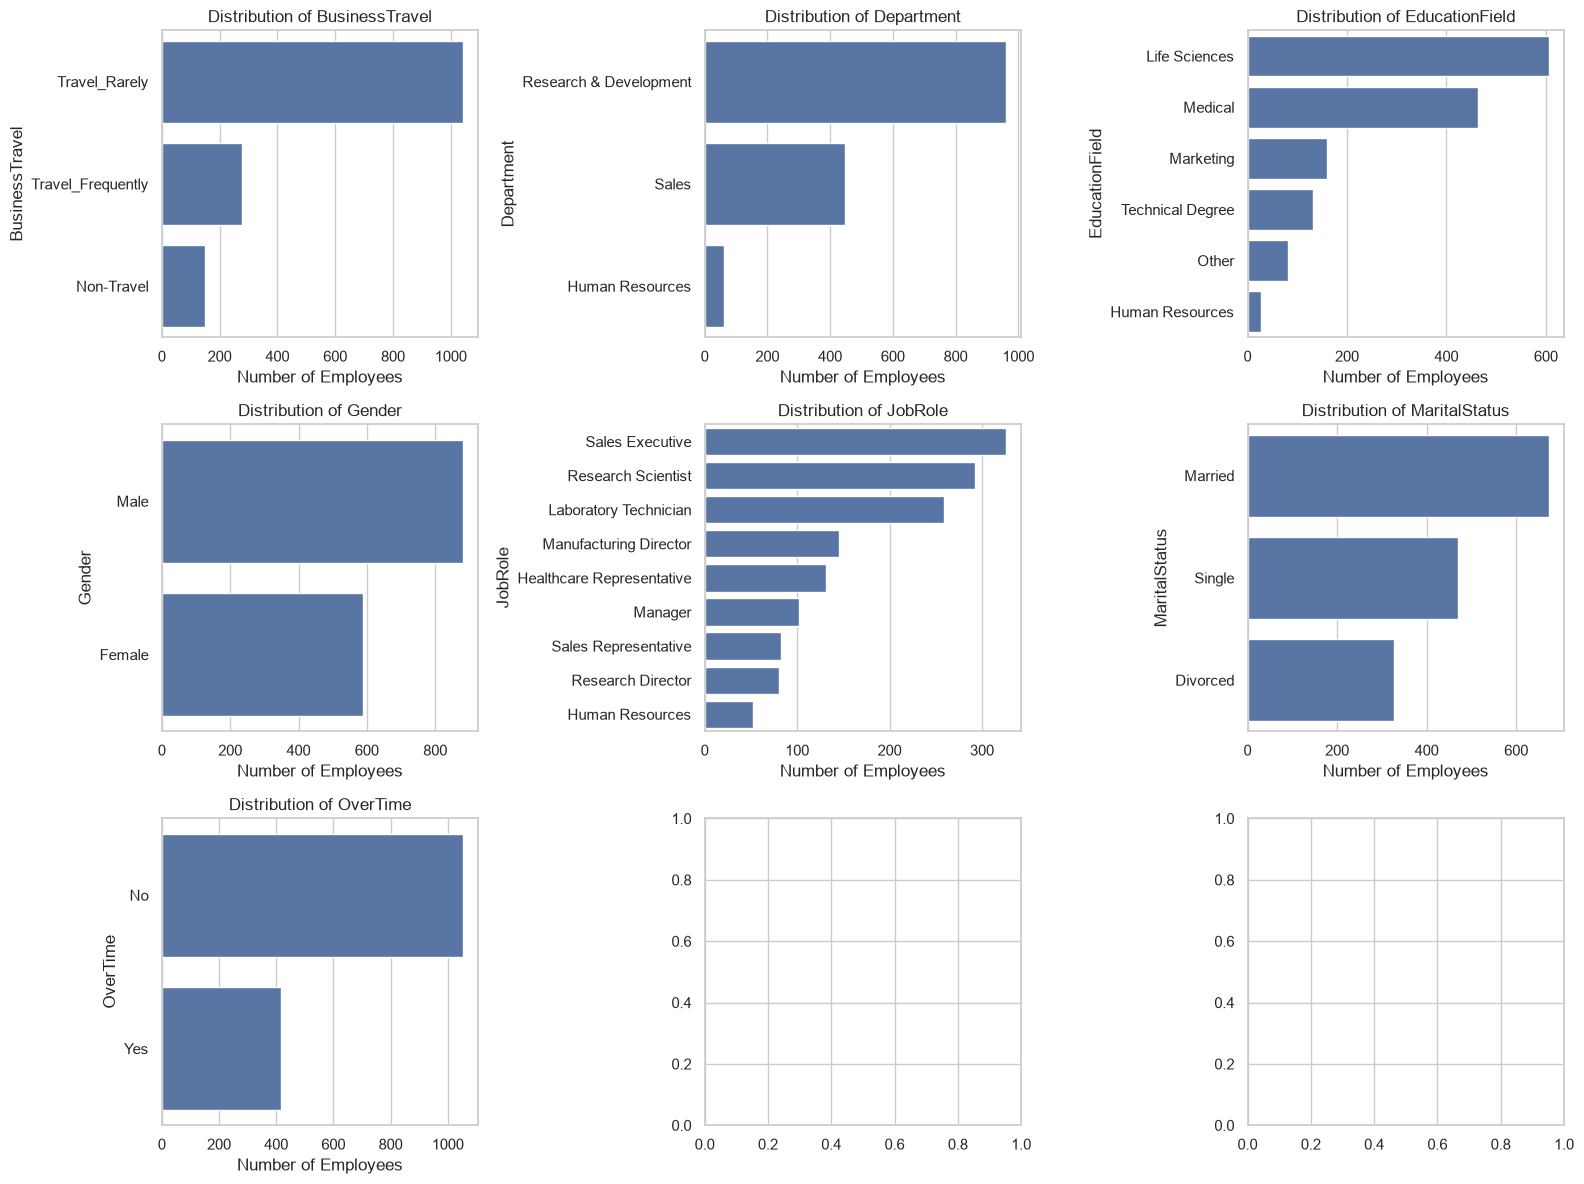

In [59]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(
        data=df,
        y=col,
        order=df[col].value_counts().index,
        ax = axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel("Number of Employees")
    axes[i].set_ylabel(col)
    
plt.tight_layout()
plt.show()    
    

1. Work Pattern & Commutative FeaturesBusinessTravel: The vast majority of employees travel rarely (~1,000+), while frequent travelers (~270) and non-travelers (~150) form minor cohorts.   OverTime: Around 72% (~1,050) of employees do not work overtime, while roughly 28% (~410) do. In attrition modeling, overtime is frequently one of the strongest binary flags for workplace burnout.   2. Departmental & Role StructureDepartment: Strongly dominated by Research & Development (~950 employees), followed by Sales (~450) and a small Human Resources unit (~60).   JobRole: Corresponds directly with department counts—line-level operational roles (Sales Executive, Research Scientist, and Laboratory Technician) form the top 3 job roles, while leadership roles (Manager, Research Director) are far fewer.   EducationField: Life Sciences (~600) and Medical (~460) make up over 70% of employee educational backgrounds, aligning with the large R&D department presence.   3. DemographicsGender: Displays a slight imbalance, with male employees (~880) outnumbering female employees (~590) at roughly a 60:40 ratio.   MaritalStatus: Married employees make up the largest subgroup (~670), followed by Single (~470) and Divorced (~330).   

#### 4. Categorical features vs Attrition

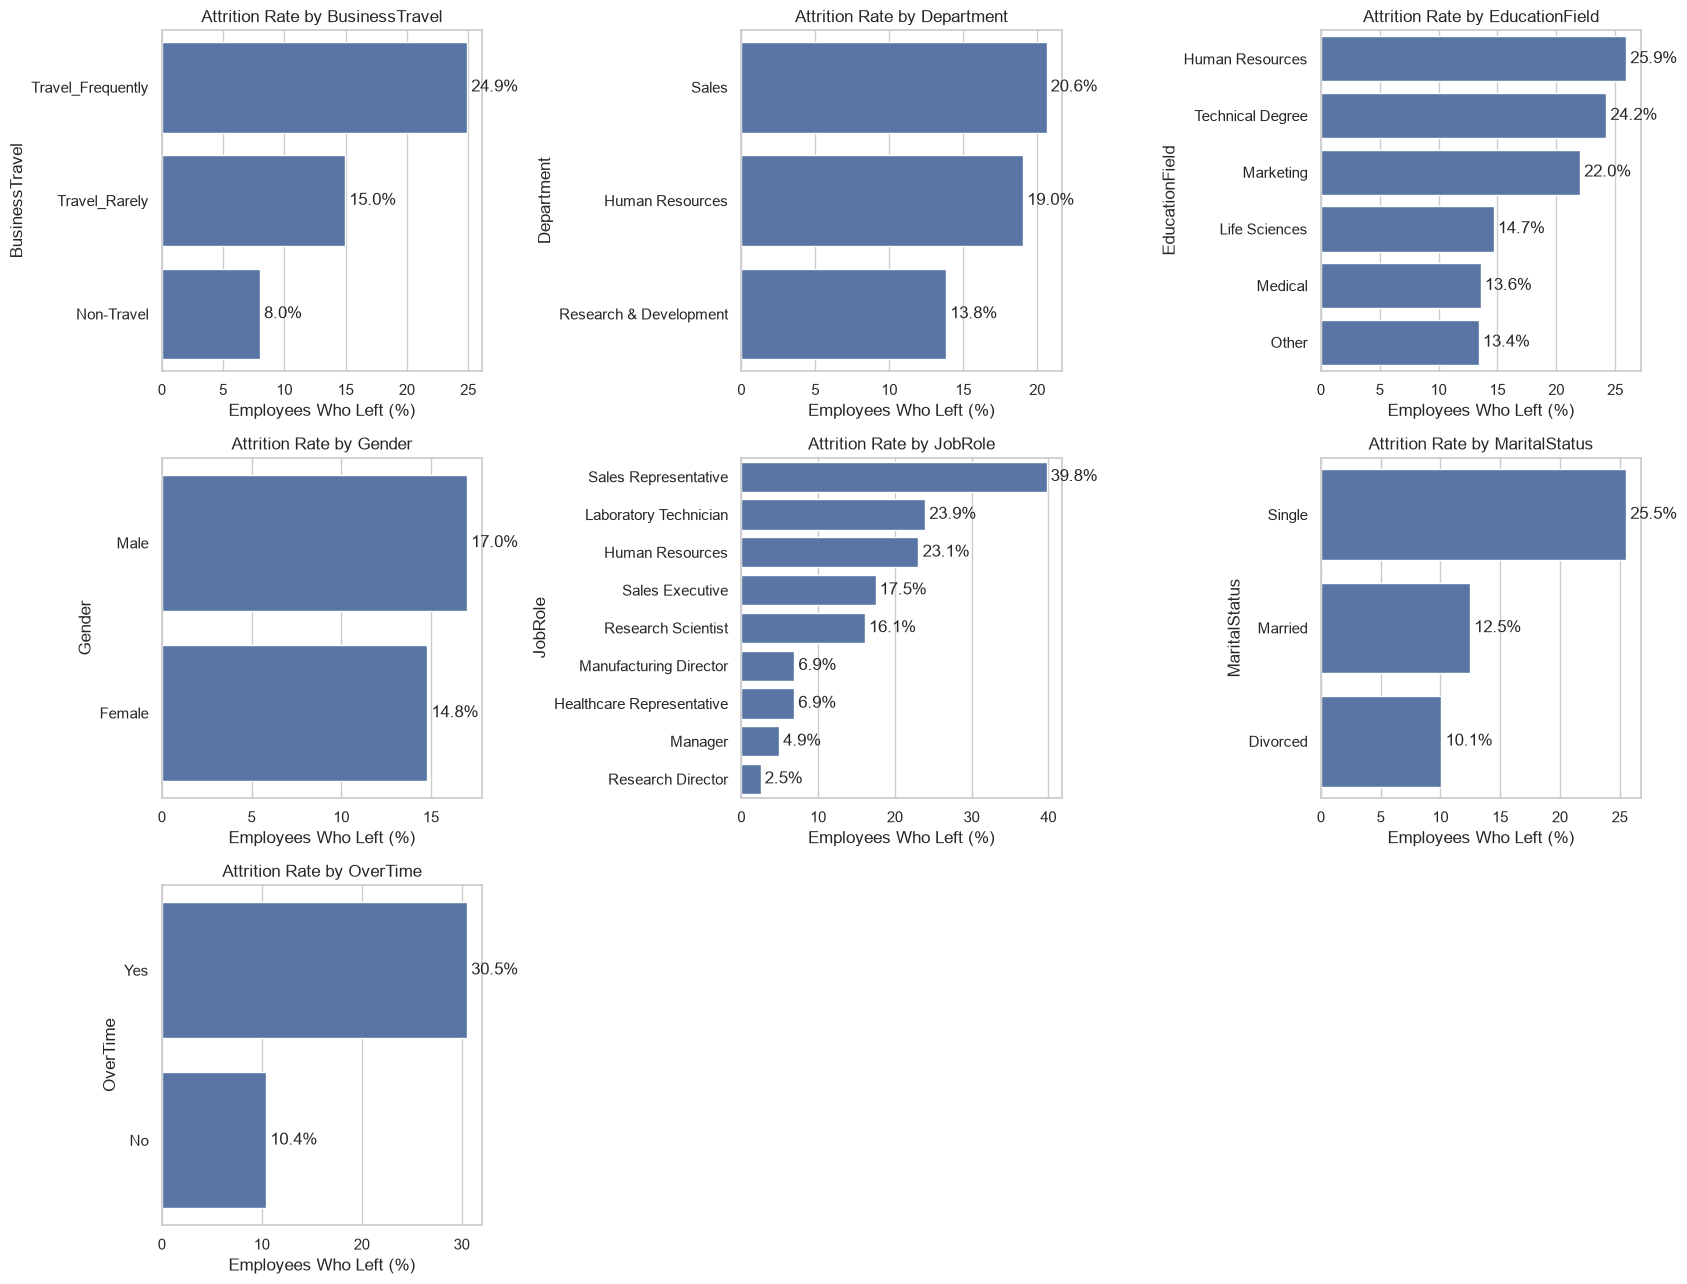

In [ ]:

fig, axes = plt.subplots(3, 3, figsize=(17, 13))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    rate = (
        df.groupby(col, observed=True)["Attrition"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
        .reset_index(name="AttritionRate")
    )

    sns.barplot(
        data=rate,
        x="AttritionRate",
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(f"Attrition Rate by {col}")
    axes[i].set_xlabel("Employees Who Left (%)")
    axes[i].set_ylabel(col)

    # Show the percentage beside each bar
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt="%.1f%%", padding=3)


plt.tight_layout()
plt.show()

1. Highest-Impact Attrition DriversOverTime: Working overtime is one of the strongest binary predictors of turnover—employees working overtime experience nearly 3x higher attrition (30.5%) compared to those who do not (10.4%).   JobRole: Attrition varies dramatically by role. Sales Representatives face the highest turnover at 39.8%, followed by Laboratory Technicians (23.9%) and Human Resources personnel (23.1%). Executive and senior roles show high stability, led by Research Directors (2.5%) and Managers (4.9%).   BusinessTravel: Travel frequency displays a direct positive relationship with turnover—frequent travelers attrite at 24.9%, compared to 15.0% for rare travelers and 8.0% for non-travelers.   MaritalStatus: Single employees leave at more than double the rate (25.5%) of Married (12.5%) or Divorced (10.1%) staff.   2. Departmental & Demographic TrendsEducationField: Employees with backgrounds in Human Resources (25.9%), Technical Degrees (24.2%), and Marketing (22.0%) show substantially higher turnover than those from Life Sciences (14.7%), Medical (13.6%), or Other fields (13.4%).   Department: Sales leads all departments in attrition (20.6%), followed by Human Resources (19.0%), while Research & Development remains the most stable (13.8%).   Gender: Male employees have a slightly higher attrition rate (17.0%) than Female employees (14.8%), indicating a minor baseline variance.   

#### 5. Ordinal features — satisfaction, education, and levels

In [74]:
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [ ]:
print(df['Education'].nunique())
print(df['EnvironmentSatisfaction'].nunique())
print(df['JobLevel'].nunique())


5
4
5


In [97]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [112]:
ord_feature = df.select_dtypes(include=["int64"]).columns.tolist()
ord_feature

['Age',
 'DailyRate',
 'DistanceFromHome',
 'Education',
 'EmployeeCount',
 'EmployeeNumber',
 'EnvironmentSatisfaction',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StandardHours',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

In [113]:
ordinal_cols = [col for col in ord_feature if df[col].nunique()<6]

In [114]:
ordinal_cols

['Education',
 'EmployeeCount',
 'EnvironmentSatisfaction',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StandardHours',
 'StockOptionLevel',
 'WorkLifeBalance']

In [115]:
ordinal_cols.remove('EmployeeCount')
ordinal_cols.remove('StandardHours')

In [116]:
ordinal_cols

['Education',
 'EnvironmentSatisfaction',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'WorkLifeBalance']

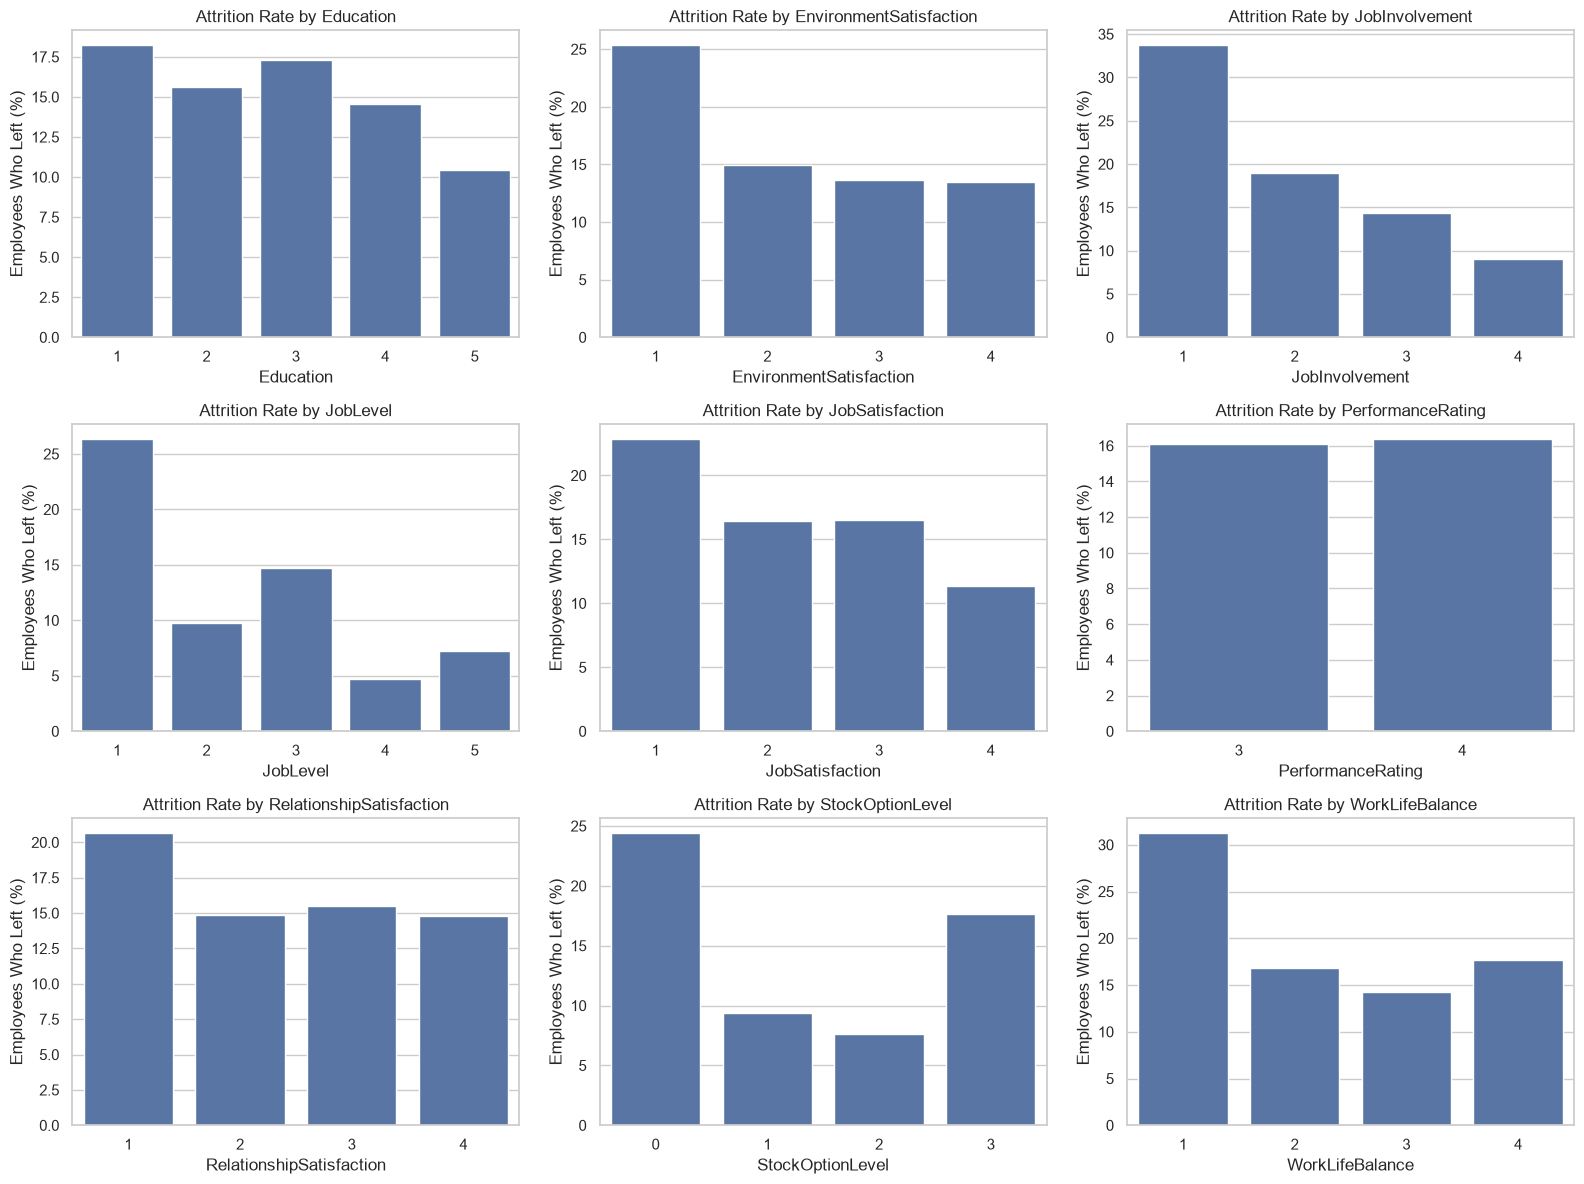

In [117]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(ordinal_cols):
    rate = (
        df.groupby(col, observed=True)["Attrition"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .reset_index(name="AttritionRate")
    )

    sns.barplot(data=rate, x=col, y="AttritionRate", ax=axes[i])
    axes[i].set_title(f"Attrition Rate by {col}")
    axes[i].set_ylabel("Employees Who Left (%)")


plt.tight_layout()
plt.show()

1. Strongest Linear & High-Contrast PredictorsJobInvolvement: Displays a steep, inverse linear relationship—employees with low job involvement (Level 1) suffer the highest attrition across all survey metrics at ~33.5%, dropping steadily to ~9.0% for highly involved staff (Level 4).   WorkLifeBalance: Poor work-life balance (Level 1) is a severe flight risk trigger, causing an attrition rate of ~31.0%, compared to ~14.0%–17.5% for higher levels.   JobLevel: Entry-level staff (Level 1) experience the highest turnover rate at ~26.5%, whereas senior roles (Level 4) drop as low as ~4.5%.   EnvironmentSatisfaction & JobSatisfaction: Both metrics show a major risk spike at Level 1 (~25.0% and ~22.5% respectively), while higher satisfaction levels (2–4) stabilize at much lower rates (11.0%–16.5%).   2. Non-Linear & U-Shaped PatternsStockOptionLevel: Exhibits a clear $U$-shaped curve—employees with no stock options (Level 0) have high turnover (~24.5%), which drops drastically for moderate option grants (Level 1 at ~9.0% and Level 2 at ~7.5%). However, attrition rises again at Level 3 (~17.5%), suggesting potential equity vesting milestones or senior executive poaching.   RelationshipSatisfaction: Low satisfaction (Level 1) drives slightly higher attrition (~20.5%), but levels 2, 3, and 4 plateau evenly around ~15.0%.   Education: Higher education levels (Level 5 / Doctorate/Master's) correspond to the lowest attrition rate (~10.5%), while lower tiers fluctuate between ~14.5%–18.0%.   3. Non-Differentiating FeaturePerformanceRating: Displays virtually identical attrition rates between rating levels (~16.0% for Level 3 vs ~16.5% for Level 4). Standalone performance evaluation scores provide almost zero predictive power for turnover risk.   Key Takeaways & Modeling StrategyHigh-Risk Employee Profile: Employees in Level 1 job roles with no stock options, poor work-life balance, and low job involvement present the highest compound probability of leaving.   Ordinal Feature Encoding: Since ordinal scores like JobInvolvement, EnvironmentSatisfaction, and JobSatisfaction show monotonic or threshold-based trends, integer encoding ($1, 2, 3, 4$) preserves their natural rank structure well for distance-based and linear models.   

#### 6. Correlation heatmap — identify relationships between numerical features

In [118]:
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'HourlyRate',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

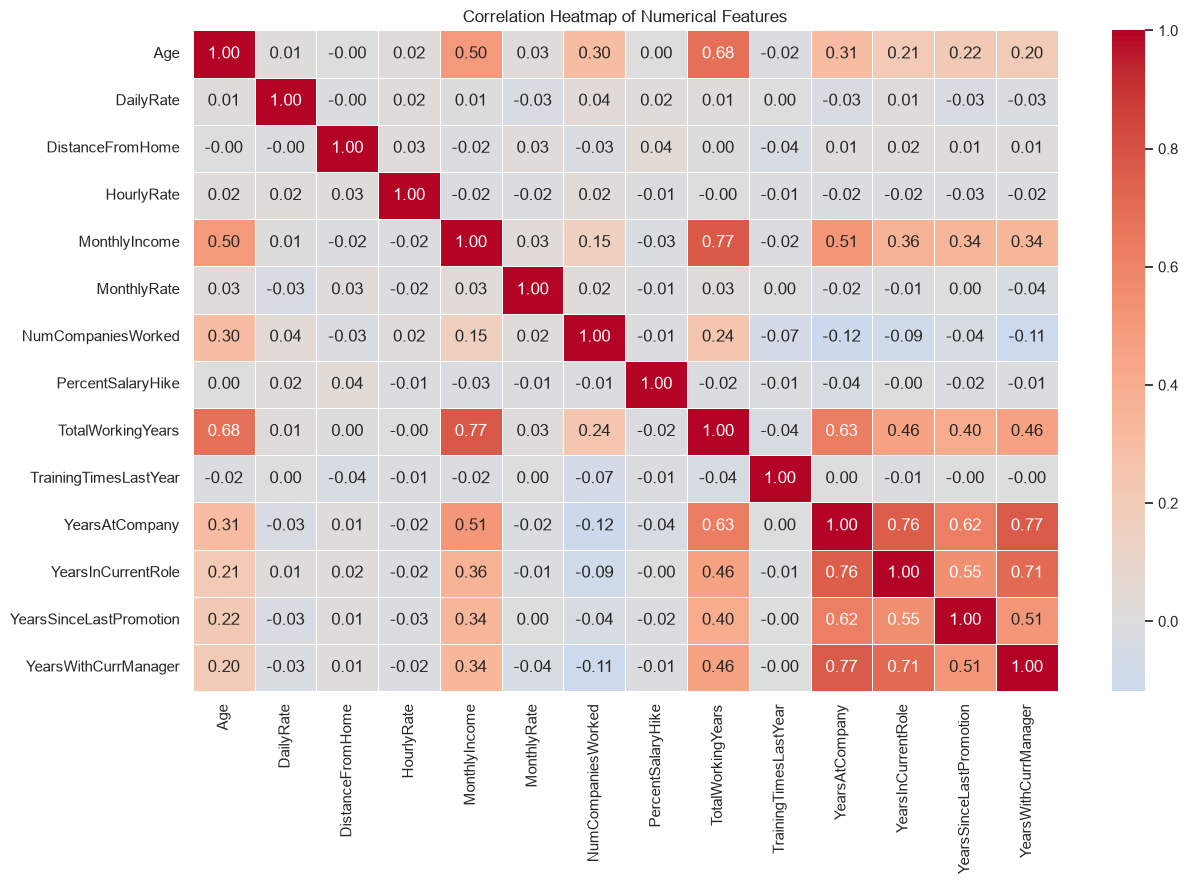

In [120]:
corr_cols = num_cols
plt.figure(figsize=(13,9))
sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

1. High Multicollinearity Clusters (Strong Positive Correlations)Experience & Compensation Cluster: TotalWorkingYears and MonthlyIncome share a very strong positive correlation ($r = 0.77$), reflecting standard compensation growth relative to cumulative career experience. Age also strongly correlates with TotalWorkingYears ($r = 0.68$) and MonthlyIncome ($r = 0.50$).   Company Tenure Cluster: Organizational tenure variables form a tightly bound cluster of high collinearity:   YearsAtCompany $\leftrightarrow$ YearsWithCurrManager ($r = 0.77$)   YearsAtCompany $\leftrightarrow$ YearsInCurrentRole ($r = 0.76$)   YearsInCurrentRole $\leftrightarrow$ YearsWithCurrManager ($r = 0.71$)   YearsAtCompany $\leftrightarrow$ TotalWorkingYears ($r = 0.63$)   YearsAtCompany $\leftrightarrow$ YearsSinceLastPromotion ($r = 0.62$)   2. Uncorrelated & Independent Features ($r \approx 0.00$)Rate Variables: DailyRate, HourlyRate, and MonthlyRate exhibit virtually zero linear correlation with each other and all other metrics (ranging between $-0.04$ and $0.04$), reinforcing earlier observations that these rate columns behave like artificially generated noise.   Independent Work Drivers: DistanceFromHome, PercentSalaryHike, and TrainingTimesLastYear operate completely independently of age, income, or organizational tenure ($r \approx 0.00$ across the board).   Machine Learning & Preprocessing TakeawaysMulticollinearity Inflation: Linear and distance-based models (such as Logistic Regression, Naive Bayes, or KNN) will suffer from inflated coefficient variance if all tenure and experience metrics are included simultaneously.   Feature Selection & Engineering:Use Variance Inflation Factor (VIF) filtering or Principal Component Analysis (PCA) to condense tenure metrics (YearsAtCompany, YearsInCurrentRole, YearsWithCurrManager, YearsSinceLastPromotion) into composite features.   Choose one primary proxy for overall career seniority (e.g., TotalWorkingYears) rather than keeping Age, TotalWorkingYears, and MonthlyIncome together without regularized models (like Lasso/Ridge). 

#### 7. Final EDA checks and feature decisions

In [121]:

# 1. Missing values
print("Total missing values:", df.isnull().sum().sum())

# 2. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 3. Constant columns
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]
print("Constant columns:", constant_cols)

# 4. Identifier column
print("EmployeeNumber unique:", df["EmployeeNumber"].is_unique)

# 5. Target distribution
print("\nTarget distribution (%):")
print((df["Attrition"].value_counts(normalize=True) * 100).round(2))

# 6. Check numerical ranges for suspicious values
print("\nNumerical summary:")
print(df[num_cols].describe().round(2).T)

Total missing values: 0
Duplicate rows: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
EmployeeNumber unique: True

Target distribution (%):
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

Numerical summary:
                          count      mean      std     min     25%      50%  \
Age                      1470.0     36.92     9.14    18.0    30.0     36.0   
DailyRate                1470.0    802.49   403.51   102.0   465.0    802.0   
DistanceFromHome         1470.0      9.19     8.11     1.0     2.0      7.0   
HourlyRate               1470.0     65.89    20.33    30.0    48.0     66.0   
MonthlyIncome            1470.0   6502.93  4707.96  1009.0  2911.0   4919.0   
MonthlyRate              1470.0  14313.10  7117.79  2094.0  8047.0  14235.5   
NumCompaniesWorked       1470.0      2.69     2.50     0.0     1.0      2.0   
PercentSalaryHike        1470.0     15.21     3.66    11.0    12.0     14.0   
TotalWorkingYears        1470.0     11.28

### CONCLUSION

## Final EDA Report — IBM HR Employee Attrition Dataset

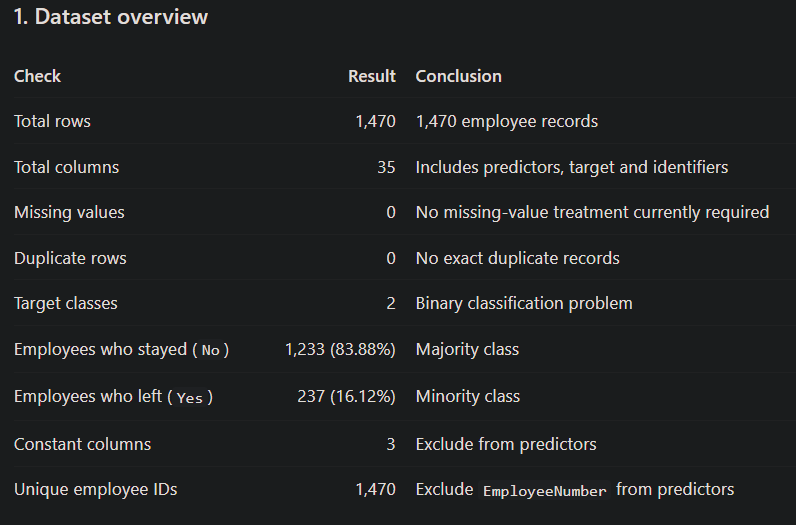

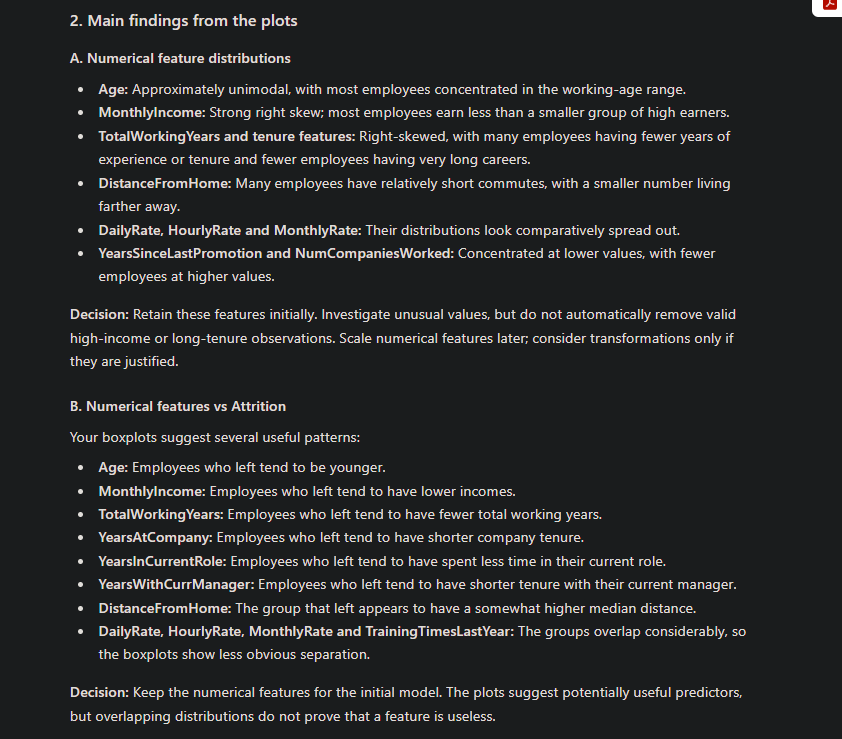

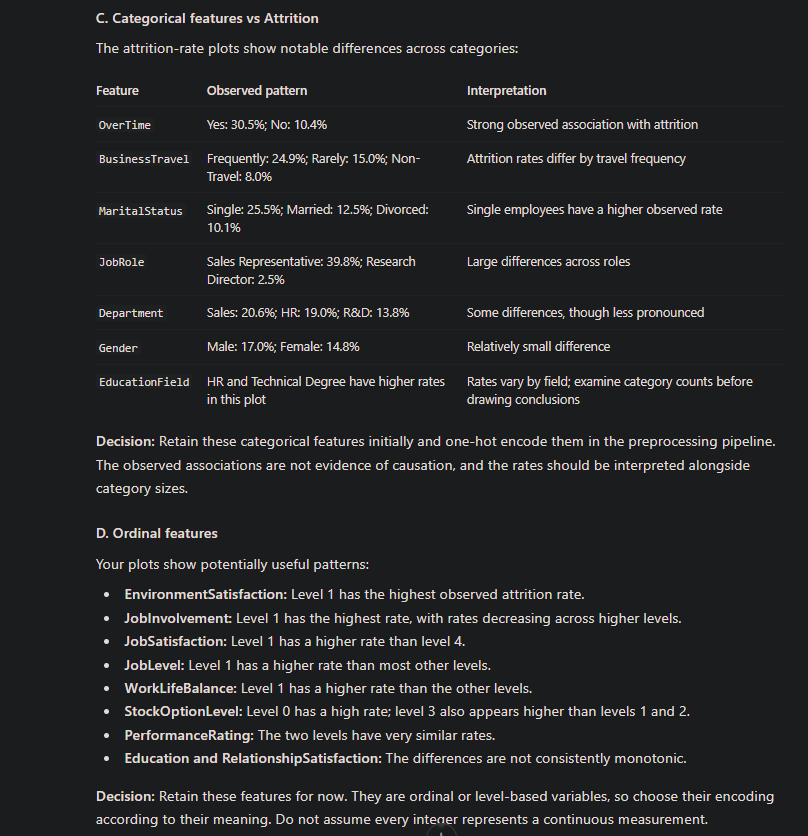

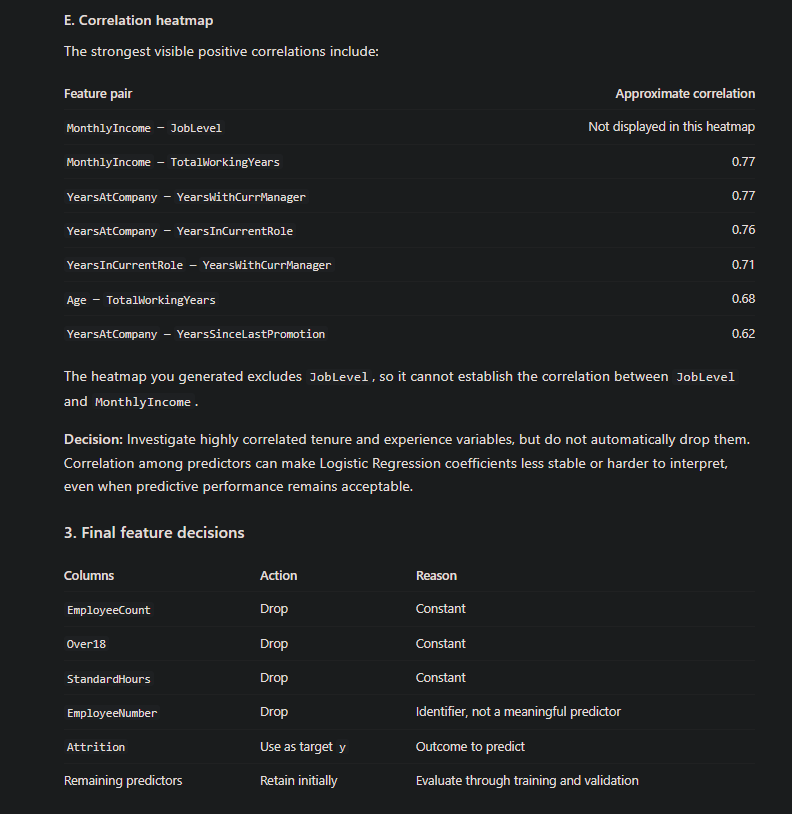

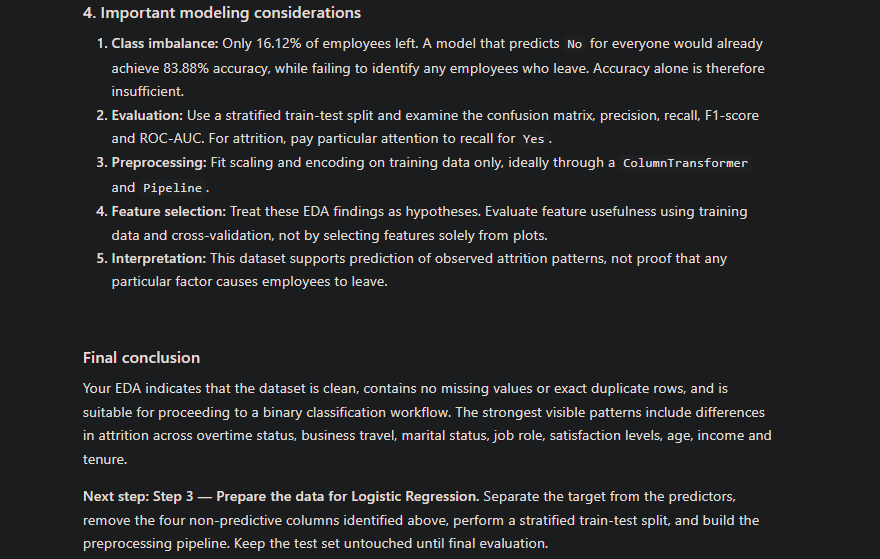